# Transaction Timeline Review and Eligible Modelling Base (Date Coverage)

**Task:** review the transaction timeline of the Online Retail II data, check the date coverage, and build an
**eligible modelling base**: one row per customer, with features from the past and a target from the future,
with no data leakage.

**Model purpose (assumption):** predict which existing customers will **buy again in the next 3 months**
(repurchase / churn model). The window lengths and cutoff date are set in one config cell (section 3) and can be changed.

**Input:** only the raw `online_retail_II.csv` in the same folder. The cleaning rules from the Data Cleaning task are applied in section 1.

**Output:** one Excel file, `Modelling_Base_Results.xlsx`, with every result on its own sheet.

**Libraries (install once):** `pip install pandas numpy matplotlib openpyxl`

**Steps:** load + clean → timeline review → date coverage → choose windows → eligibility rules → features + target → validation → save results

### What is new in version 2
- **Snapshots (section 6):** the same modelling base is built at 4 cutoff dates (3 development + 1 out-of-time test), with 10 snapshot checks
- **Feature stability (section 6.2):** PSI for every feature between the development and out-of-time data
- **Feature correlation (section 7):** Spearman correlation heatmap and the list of highly correlated feature pairs
- New Excel sheets: snapshots_summary, all_snapshots, snapshot_checks, feature_stability_psi, feature_correlation

## 1. Import libraries, load and clean the data

The same cleaning rules as the Data Cleaning task are used, so this notebook only needs the raw CSV.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 120)

In [2]:
raw = pd.read_csv('online_retail_II.csv', dtype={'Invoice': str, 'StockCode': str})
df = raw.rename(columns={'Customer ID': 'CustomerID'})
cleaning_log = []

def log(step, before):
    cleaning_log.append({'Step': step, 'Rows removed': before - len(df), 'Rows left': len(df)})

before = len(df); df = df.drop_duplicates(); log('Duplicate rows', before)

df['Invoice'] = df['Invoice'].str.strip()
df['StockCode'] = df['StockCode'].str.strip().str.upper()
df['Description'] = df['Description'].str.strip()
df['Country'] = df['Country'].str.strip().replace({'EIRE': 'Ireland', 'RSA': 'South Africa'})

# missing Description: fill from the same StockCode, remove if the product is unknown
code_names = df.dropna(subset=['Description']).groupby('StockCode')['Description'].agg(lambda x: x.mode()[0])
missing = df['Description'].isnull()
df.loc[missing, 'Description'] = df.loc[missing, 'StockCode'].map(code_names)
before = len(df); df = df.dropna(subset=['Description']); log('Missing Description (unknown product)', before)

before = len(df); df = df[~df['Invoice'].str.startswith('C')]; log('Cancelled orders (C invoices)', before)
before = len(df); df = df[~df['Invoice'].str.startswith('A')]; log('Bad-debt adjustments (A invoices)', before)
before = len(df); df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]; log('Quantity or Price <= 0', before)

not_products = ['POST', 'DOT', 'M', 'C2', 'D', 'S', 'BANK CHARGES', 'ADJUST', 'ADJUST2',
                'AMAZONFEE', 'PADS', 'CRUK', 'B', 'TEST001', 'TEST002']
before = len(df)
df = df[~(df['StockCode'].isin(not_products) | df['StockCode'].str.startswith('GIFT'))]
log('Non-product codes (postage, fees, tests...)', before)

before = len(df); df = df[df['Quantity'] < 70000]; log('2 cancelled mega-orders (outliers)', before)
before = len(df); df = df.drop_duplicates(); log('Duplicates after text fix', before)

df['CustomerID'] = df['CustomerID'].astype('Int64')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Revenue'] = (df['Quantity'] * df['Price']).round(2)
df['Date'] = df['InvoiceDate'].dt.normalize()
df = df.reset_index(drop=True)

cleaning_log = pd.DataFrame(cleaning_log)
print('Raw rows  :', len(raw))
print('Clean rows:', len(df), '(same as the Data Cleaning task: 1,003,338)')
print('Invoices  :', df['Invoice'].nunique())
print('Customers :', df['CustomerID'].nunique())
assert len(df) == 1003338, 'Cleaned data is different from the Data Cleaning task'
cleaning_log

Raw rows  : 1067371
Clean rows: 1003338 (same as the Data Cleaning task: 1,003,338)
Invoices  : 39514
Customers : 5852


,Step,Rows removed,Rows left
0,Duplicate rows,34335,1033036
1,Missing Description (unknown product),361,1032675
2,Cancelled orders (C invoices),19104,1013571
3,Bad-debt adjustments (A invoices),6,1013565
4,Quantity or Price <= 0,5653,1007912
5,"Non-product codes (postage, fees, tests...)",4572,1003340
6,2 cancelled mega-orders (outliers),2,1003338
7,Duplicates after text fix,0,1003338


## 2. Transaction timeline review

### 2.1 Date range

In [3]:
data_start = df['Date'].min()
data_end = df['Date'].max()
calendar_days = (data_end - data_start).days + 1
trading_days = df['Date'].nunique()

print('First transaction:', df['InvoiceDate'].min())
print('Last transaction :', df['InvoiceDate'].max())
print('Calendar days    :', calendar_days)
print('Days with sales  :', trading_days)
print('Days without sales:', calendar_days - trading_days)

First transaction: 2009-12-01 07:45:00
Last transaction : 2011-12-09 12:50:00
Calendar days    : 739
Days with sales  : 604
Days without sales: 135


### 2.2 Daily timeline

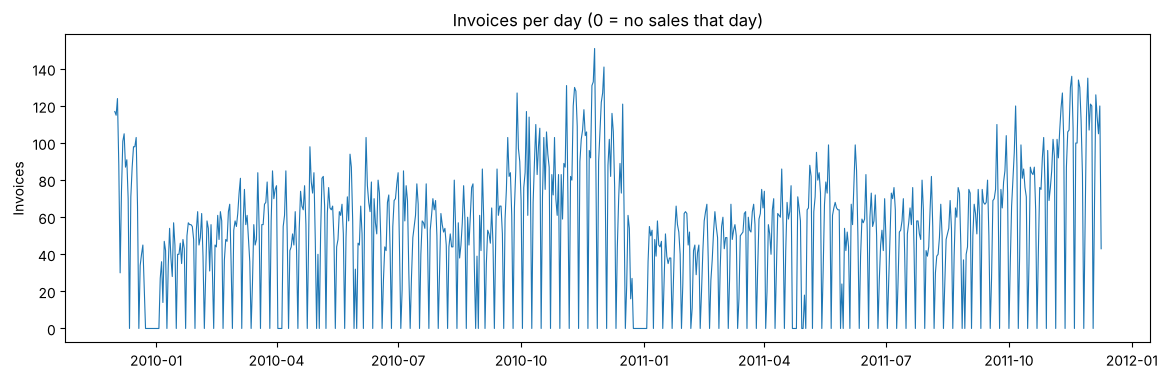

In [4]:
daily = df.groupby('Date').agg(invoices=('Invoice', 'nunique'), revenue=('Revenue', 'sum'))
daily = daily.reindex(pd.date_range(data_start, data_end), fill_value=0)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily['invoices'], linewidth=0.8)
ax.set_title('Invoices per day (0 = no sales that day)')
ax.set_ylabel('Invoices')
plt.show()

### 2.3 Days without sales: expected or a data problem?

A day with no sales is only a problem if the business was open that day. I check each empty day against:
- **Saturday**: the business does not trade on Saturdays
- **UK bank holidays** (England and Wales, 2009-2011)
- **Christmas / New Year closure**: 24 December to 3 January
- **Easter Sunday** (the business closes for the whole Easter weekend)

Any other empty day is an **unexplained gap** and could mean missing data.

In [5]:
uk_bank_holidays = pd.to_datetime([
    '2009-12-25', '2009-12-28',
    '2010-01-01', '2010-04-02', '2010-04-05', '2010-05-03', '2010-05-31', '2010-08-30', '2010-12-27', '2010-12-28',
    '2011-01-03', '2011-04-22', '2011-04-25', '2011-04-29', '2011-05-02', '2011-05-30', '2011-08-29', '2011-12-26', '2011-12-27',
])
easter_sundays = pd.to_datetime(['2010-04-04', '2011-04-24'])

def day_type(day):
    if day.day_name() == 'Saturday':
        return 'Saturday (business closed)'
    if day in uk_bank_holidays:
        return 'UK bank holiday'
    if (day.month == 12 and day.day >= 24) or (day.month == 1 and day.day <= 3):
        return 'Christmas / New Year closure'
    if day in easter_sundays:
        return 'Easter Sunday'
    return 'Normal trading day'

calendar = pd.DataFrame({'Date': pd.date_range(data_start, data_end)})
calendar['day_type'] = calendar['Date'].apply(day_type)
calendar['has_sales'] = calendar['Date'].isin(df['Date'])

no_sales = calendar[~calendar['has_sales']].copy()
no_sales['reason'] = no_sales['day_type'].replace({'Normal trading day': 'UNEXPLAINED GAP'})
print('Days without sales by reason:')
no_sales['reason'].value_counts()

Days without sales by reason:


reason
Saturday (business closed)      104
UK bank holiday                  17
Christmas / New Year closure     12
Easter Sunday                     2
Name: count, dtype: int64

In [6]:
# empty days that are NOT Saturdays
no_sales[no_sales['reason'] != 'Saturday (business closed)'][['Date', 'reason']].assign(
    weekday=lambda x: x['Date'].dt.day_name()).reset_index(drop=True)

,Date,reason,weekday
0,2009-12-24,Christmas / New Year closure,Thursday
1,2009-12-25,UK bank holiday,Friday
2,2009-12-27,Christmas / New Year closure,Sunday
3,2009-12-28,UK bank holiday,Monday
4,2009-12-29,Christmas / New Year closure,Tuesday
5,2009-12-30,Christmas / New Year closure,Wednesday
6,2009-12-31,Christmas / New Year closure,Thursday
7,2010-01-01,UK bank holiday,Friday
8,2010-01-03,Christmas / New Year closure,Sunday
9,2010-04-02,UK bank holiday,Friday


In [7]:
unexplained_gaps = no_sales[no_sales['reason'] == 'UNEXPLAINED GAP']
print('Unexplained gaps:', len(unexplained_gaps))

saturday_sales = calendar[calendar['has_sales'] & (calendar['day_type'] == 'Saturday (business closed)')]
print('Sales on a Saturday:', saturday_sales['Date'].dt.date.tolist(),
      '| rows:', len(df[df['Date'].isin(saturday_sales['Date'])]))

Unexplained gaps: 0
Sales on a Saturday: [datetime.date(2009, 12, 5)] | rows: 400


Every day without sales is explained by a Saturday, a UK bank holiday or the Christmas closure, so **no days of data are missing**.
There is one Saturday with sales (5-Dec-2009, 400 rows). It is a real trading day at the start of the data and does not affect the modelling windows, so it is kept.

### 2.4 Monthly date coverage

In [8]:
calendar['Month'] = calendar['Date'].dt.to_period('M')
calendar['expected_trading_day'] = calendar['day_type'] == 'Normal trading day'

coverage = calendar.groupby('Month').agg(
    calendar_days_in_data=('Date', 'count'),
    expected_trading_days=('expected_trading_day', 'sum'),
    expected_days_with_sales=('has_sales', lambda s: (s & calendar.loc[s.index, 'expected_trading_day']).sum()),
    sales_on_closed_days=('has_sales', lambda s: (s & ~calendar.loc[s.index, 'expected_trading_day']).sum()),
)
coverage['coverage_%'] = (coverage['expected_days_with_sales'] / coverage['expected_trading_days'] * 100).round(1)

monthly = df.assign(Month=df['InvoiceDate'].dt.to_period('M')).groupby('Month').agg(
    rows=('Invoice', 'size'), invoices=('Invoice', 'nunique'), customers=('CustomerID', 'nunique'),
    revenue=('Revenue', 'sum'), guest_rows_pct=('CustomerID', lambda s: round(s.isnull().mean() * 100, 1)))
coverage = coverage.join(monthly)
coverage['revenue'] = coverage['revenue'].round(2)

# a month is complete only if the data covers every calendar day of it
coverage['complete_month'] = coverage['calendar_days_in_data'] == coverage.index.days_in_month
coverage['status'] = np.where(coverage['complete_month'], 'Complete',
                              'Partial (data ends ' + data_end.strftime('%d-%b-%Y') + ')')
coverage

,calendar_days_in_data,expected_trading_days,expected_days_with_sales,sales_on_closed_days,coverage_%,rows,invoices,customers,revenue,guest_rows_pct,complete_month,status
Month,,,,,,,,,,,,
2009-12,31,20,20,1,100.0,43320,1666,951,797901.16,30.3,True,Complete
2010-01,31,24,24,0,100.0,30176,1049,701,612297.42,29.2,True,Complete
2010-02,28,24,24,0,100.0,27811,1189,771,537909.67,17.5,True,Complete
2010-03,31,27,27,0,100.0,39609,1647,1051,761705.98,20.1,True,Complete
2010-04,30,23,23,0,100.0,32665,1435,939,646340.93,18.2,True,Complete
2010-05,31,24,24,0,100.0,33226,1484,965,643492.03,15.3,True,Complete
2010-06,30,26,26,0,100.0,38211,1612,1034,696583.19,19.9,True,Complete
2010-07,31,26,26,0,100.0,31943,1507,924,632994.32,16.9,True,Complete
2010-08,31,26,26,0,100.0,31953,1402,910,674037.72,18.8,True,Complete


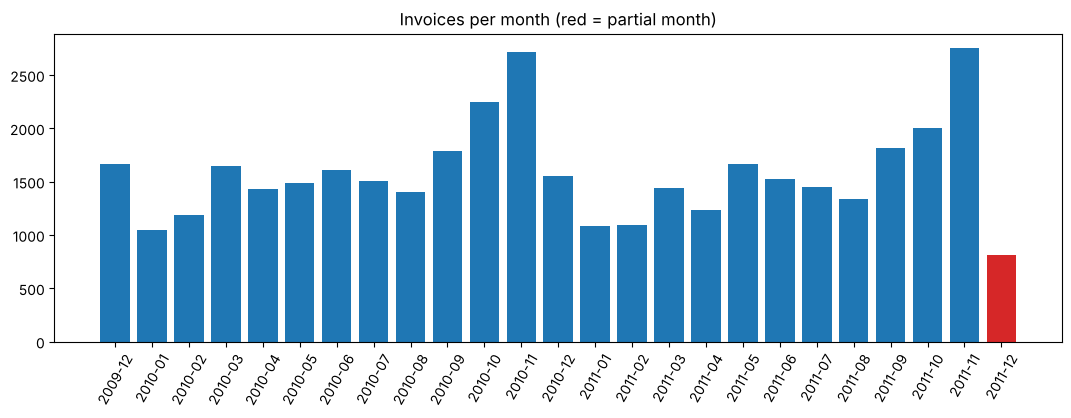

Months with coverage below 100%: 0
Partial months: ['2011-12']


In [9]:
fig, ax = plt.subplots(figsize=(13, 4))
colors = ['tab:blue' if c else 'tab:red' for c in coverage['complete_month']]
ax.bar(coverage.index.astype(str), coverage['invoices'], color=colors)
ax.set_title('Invoices per month (red = partial month)')
ax.tick_params(axis='x', rotation=60)
plt.show()

print('Months with coverage below 100%:', (coverage['coverage_%'] < 100).sum())
print('Partial months:', coverage.index[~coverage['complete_month']].astype(str).tolist())

- All 25 months have sales on **100% of their expected trading days**.
- **December 2011 is partial**: the data stops on 9-Dec-2011. Its sales look low only because the month is cut off,
  so it must **not** be used as a full month in the model.

### 2.5 CustomerID coverage over time

A model is built per customer, so rows without a CustomerID (guest sales) cannot be used.

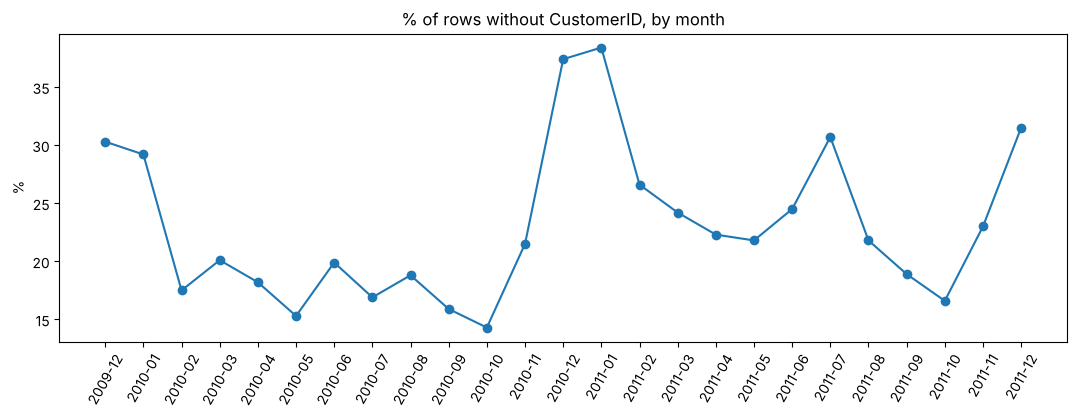

Guest rows overall: 22.6 %
Lowest month : 2010-10 14.3 %
Highest month: 2011-01 38.4 %


In [10]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(coverage.index.astype(str), coverage['guest_rows_pct'], marker='o')
ax.set_title('% of rows without CustomerID, by month')
ax.set_ylabel('%')
ax.tick_params(axis='x', rotation=60)
plt.show()

print('Guest rows overall:', round(df['CustomerID'].isnull().mean() * 100, 1), '%')
print('Lowest month :', coverage['guest_rows_pct'].idxmin(), coverage['guest_rows_pct'].min(), '%')
print('Highest month:', coverage['guest_rows_pct'].idxmax(), coverage['guest_rows_pct'].max(), '%')

Guest rows are 14% to 38% of each month (higher in December and January). They are excluded from the modelling base
because they cannot be linked to a customer. This is a known limit: the model describes registered customers only.

### 2.6 How long do customers take to order again?

This decides the length of the **performance window** (the future period in which we check if the customer bought again).

In [11]:
known = df.dropna(subset=['CustomerID'])
orders = known.groupby(['CustomerID', 'Invoice'])['InvoiceDate'].min().reset_index().sort_values(['CustomerID', 'InvoiceDate'])
orders['days_since_previous_order'] = orders.groupby('CustomerID')['InvoiceDate'].diff().dt.days
gaps = orders['days_since_previous_order'].dropna()

print('Repeat orders:', len(gaps))
print('Median days between orders:', gaps.median())
for days in [30, 60, 90, 180]:
    print(f'Next order within {days} days: {(gaps <= days).mean() * 100:.1f}%')

Repeat orders: 30740
Median days between orders: 25.0
Next order within 30 days: 55.6%
Next order within 60 days: 74.6%
Next order within 90 days: 83.2%
Next order within 180 days: 93.6%


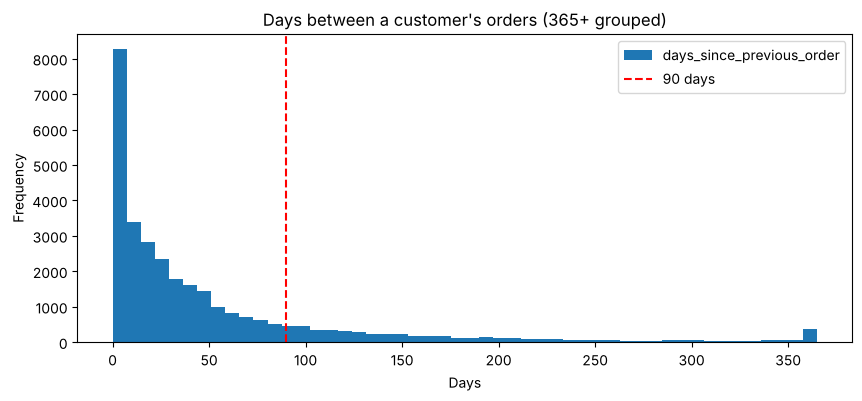

In [12]:
gaps.clip(upper=365).plot(kind='hist', bins=50, figsize=(10, 4))
plt.axvline(90, color='red', linestyle='--', label='90 days')
plt.title('Days between a customer\'s orders (365+ grouped)')
plt.xlabel('Days')
plt.legend()
plt.show()

83% of repeat orders happen within 90 days of the previous order, so a **3-month performance window** catches most real
repeat purchases without waiting too long.

## 3. Modelling windows

| Window | Dates | Used for |
|---|---|---|
| History | data start → day before observation window | Only to find each customer's first purchase (tenure) |
| **Observation window** | 12 full months before the cutoff | Customer **features** |
| **Cutoff date** | 1-Sep-2011 | The "today" of the model: nothing after it is used for features |
| **Performance window** | 3 full months from the cutoff | The **target**: did the customer buy again? |
| Excluded | December 2011 | Partial month |

The cutoff is the **latest** date that still leaves 3 complete months before the partial December 2011,
so the model uses the most recent data possible.

In [13]:
CUTOFF = pd.Timestamp('2011-09-01')
OBSERVATION_MONTHS = 12
PERFORMANCE_MONTHS = 3
MIN_TENURE_DAYS = 30

obs_start = CUTOFF - pd.DateOffset(months=OBSERVATION_MONTHS)
perf_end = CUTOFF + pd.DateOffset(months=PERFORMANCE_MONTHS)          # first day AFTER the performance window
first_partial_month_start = coverage.index[~coverage['complete_month']].min().to_timestamp()

print('Observation window :', obs_start.date(), 'to', (CUTOFF - pd.Timedelta(days=1)).date())
print('Cutoff date        :', CUTOFF.date())
print('Performance window :', CUTOFF.date(), 'to', (perf_end - pd.Timedelta(days=1)).date())
print('First partial month starts:', first_partial_month_start.date())
assert perf_end <= first_partial_month_start, 'The performance window goes into a partial month'

Observation window : 2010-09-01 to 2011-08-31
Cutoff date        : 2011-09-01
Performance window : 2011-09-01 to 2011-11-30
First partial month starts: 2011-12-01


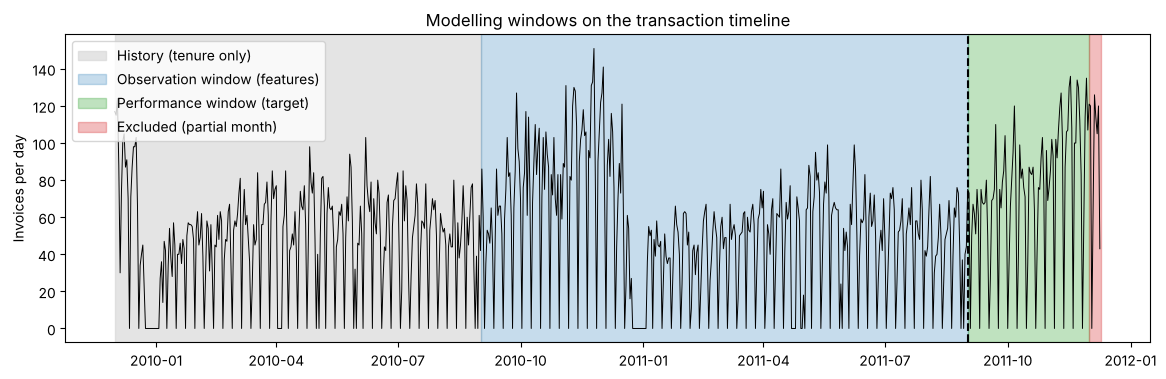

In [14]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily['invoices'], linewidth=0.7, color='black')
ax.axvspan(data_start, obs_start, color='lightgrey', alpha=0.6, label='History (tenure only)')
ax.axvspan(obs_start, CUTOFF, color='tab:blue', alpha=0.25, label='Observation window (features)')
ax.axvspan(CUTOFF, perf_end, color='tab:green', alpha=0.3, label='Performance window (target)')
ax.axvspan(perf_end, data_end + pd.Timedelta(days=1), color='tab:red', alpha=0.3, label='Excluded (partial month)')
ax.axvline(CUTOFF, color='black', linestyle='--')
ax.set_title('Modelling windows on the transaction timeline')
ax.set_ylabel('Invoices per day')
ax.legend(loc='upper left')
plt.show()

In [15]:
window_coverage = coverage[(coverage.index.to_timestamp() >= obs_start) & (coverage.index.to_timestamp() < perf_end)].copy()
window_coverage['window'] = np.where(window_coverage.index.to_timestamp() < CUTOFF, 'Observation', 'Performance')
window_coverage[['window', 'expected_trading_days', 'expected_days_with_sales', 'coverage_%', 'invoices', 'customers', 'status']]

,window,expected_trading_days,expected_days_with_sales,coverage_%,invoices,customers,status
Month,,,,,,,
2010-09,Observation,26,26,100.0,1789,1136,Complete
2010-10,Observation,26,26,100.0,2244,1492,Complete
2010-11,Observation,26,26,100.0,2719,1606,Complete
2010-12,Observation,20,20,100.0,1550,884,Complete
2011-01,Observation,24,24,100.0,1080,738,Complete
2011-02,Observation,24,24,100.0,1093,757,Complete
2011-03,Observation,27,27,100.0,1440,973,Complete
2011-04,Observation,21,21,100.0,1235,853,Complete
2011-05,Observation,25,25,100.0,1668,1054,Complete


## 4. Eligible modelling base

### 4.1 Eligibility rules

| Rule | Reason |
|---|---|
| Has a CustomerID | Guest sales cannot be linked to a customer |
| First purchase before the cutoff | Customers who first appear after the cutoff did not exist on the cutoff date |
| At least 1 order in the observation window | Customers with no order in the last 12 months have already left; they are a different problem (win-back) |
| First purchase at least 30 days before the cutoff | Too little history to describe the customer |

In [16]:
first_purchase = known.groupby('CustomerID')['InvoiceDate'].min()
obs_customers = set(known[(known['InvoiceDate'] >= obs_start) & (known['InvoiceDate'] < CUTOFF)]['CustomerID'])

waterfall = []
def add_step(rule, reason, customers_left):
    previous = waterfall[-1]['Customers left'] if waterfall else None
    waterfall.append({'Rule': rule, 'Reason': reason,
                      'Customers removed': 0 if previous is None else previous - len(customers_left),
                      'Customers left': len(customers_left)})
    return customers_left

eligible = add_step('All customers with a CustomerID', f"{df['CustomerID'].isnull().sum()} guest rows have no CustomerID",
                    set(first_purchase.index))
eligible = add_step('First purchase before the cutoff', 'New customers who first bought on or after the cutoff',
                    {c for c in eligible if first_purchase[c] < CUTOFF})
eligible = add_step('At least 1 order in the observation window', 'No order in the 12 months before the cutoff (already lapsed)',
                    {c for c in eligible if c in obs_customers})
eligible = add_step(f'First purchase at least {MIN_TENURE_DAYS} days before the cutoff', 'Too little history',
                    {c for c in eligible if (CUTOFF - first_purchase[c]).days >= MIN_TENURE_DAYS})

waterfall = pd.DataFrame(waterfall)
waterfall['% of all customers left'] = (waterfall['Customers left'] / waterfall['Customers left'].iloc[0] * 100).round(1)
waterfall

,Rule,Reason,Customers removed,Customers left,% of all customers left
0,All customers with a CustomerID,226761 guest rows have no CustomerID,0,5852,100.0
1,First purchase before the cutoff,New customers who first bought on or after the cutoff,628,5224,89.3
2,At least 1 order in the observation window,No order in the 12 months before the cutoff (already lapsed),901,4323,73.9
3,First purchase at least 30 days before the cutoff,Too little history,102,4221,72.1


### 4.2 Features (only from data **before** the cutoff)

All features are built from transactions dated **before 1-Sep-2011**. The function only receives the data it is allowed to see.

In [17]:
def build_features(transactions, customer_list, cutoff=CUTOFF, obs_start=obs_start):
    # only data before the cutoff can be used
    past = transactions[(transactions['InvoiceDate'] < cutoff) & transactions['CustomerID'].isin(customer_list)]
    obs = past[past['InvoiceDate'] >= obs_start]
    last_3m = obs[obs['InvoiceDate'] >= cutoff - pd.DateOffset(months=3)]
    same_period_last_year = obs[obs['InvoiceDate'] < obs_start + pd.DateOffset(months=PERFORMANCE_MONTHS)]

    f = pd.DataFrame(index=pd.Index(sorted(customer_list), name='customer_id'))
    f['recency_days'] = (cutoff - obs.groupby('CustomerID')['Date'].max()).dt.days
    f['tenure_days'] = (cutoff - past.groupby('CustomerID')['Date'].min()).dt.days
    f['frequency_12m'] = obs.groupby('CustomerID')['Invoice'].nunique()
    f['monetary_12m'] = obs.groupby('CustomerID')['Revenue'].sum().round(2)
    f['avg_order_value_12m'] = (f['monetary_12m'] / f['frequency_12m']).round(2)
    f['units_12m'] = obs.groupby('CustomerID')['Quantity'].sum()
    f['distinct_products_12m'] = obs.groupby('CustomerID')['StockCode'].nunique()
    f['active_months_12m'] = obs.groupby('CustomerID')['InvoiceDate'].apply(lambda s: s.dt.to_period('M').nunique())
    f['orders_last_3m'] = last_3m.groupby('CustomerID')['Invoice'].nunique()
    f['revenue_last_3m'] = last_3m.groupby('CustomerID')['Revenue'].sum().round(2)
    f['orders_same_period_last_year'] = same_period_last_year.groupby('CustomerID')['Invoice'].nunique()
    f['is_uk'] = (past.groupby('CustomerID')['Country'].agg(lambda s: s.mode()[0]) == 'United Kingdom').astype(int)

    count_cols = ['orders_last_3m', 'revenue_last_3m', 'orders_same_period_last_year']
    f[count_cols] = f[count_cols].fillna(0)    # no orders in that period = 0
    return f

features = build_features(known, eligible)
print('Feature rows:', len(features))
features.head()

Feature rows: 4221


,recency_days,tenure_days,frequency_12m,monetary_12m,avg_order_value_12m,units_12m,distinct_products_12m,active_months_12m,orders_last_3m,revenue_last_3m,orders_same_period_last_year,is_uk
customer_id,,,,,,,,,,,,
12347,30,305,6,3402.39,567.06,2099,107,6,2.0,967.43,1.0,0
12348,149,339,4,1388.40,347.10,2488,24,4,0.0,0.00,1.0,0
12349,308,490,1,1152.62,1152.62,518,54,1,0.0,0.00,1.0,0
12350,211,211,1,294.40,294.40,196,16,1,0.0,0.00,0.0,0
12351,276,276,1,300.93,300.93,261,21,1,0.0,0.00,1.0,0


### 4.3 Target (only from the performance window)

- `target_purchased_next_3m` = 1 if the customer placed at least one order between 1-Sep-2011 and 30-Nov-2011, otherwise 0
- `target_revenue_next_3m` = money spent in the same 3 months (for a possible spend model later)

These two columns are the **answers** and must never be used as features.

In [18]:
perf = known[(known['InvoiceDate'] >= CUTOFF) & (known['InvoiceDate'] < perf_end) & known['CustomerID'].isin(eligible)]

base = features.copy()
base['target_purchased_next_3m'] = base.index.isin(perf['CustomerID']).astype(int)
base['target_revenue_next_3m'] = perf.groupby('CustomerID')['Revenue'].sum().round(2).reindex(base.index).fillna(0)
base = base.reset_index()

print('Modelling base rows:', len(base))
print('Customers who bought again (target = 1):', base['target_purchased_next_3m'].sum())
print('Target rate:', round(base['target_purchased_next_3m'].mean() * 100, 1), '%')
base.head()

Modelling base rows: 4221
Customers who bought again (target = 1): 2096
Target rate: 49.7 %


,customer_id,recency_days,tenure_days,frequency_12m,monetary_12m,avg_order_value_12m,units_12m,distinct_products_12m,active_months_12m,orders_last_3m,revenue_last_3m,orders_same_period_last_year,is_uk,target_purchased_next_3m,target_revenue_next_3m
0,12347,30,305,6,3402.39,567.06,2099,107,6,2.0,967.43,1.0,0,1,1294.32
1,12348,149,339,4,1388.40,347.10,2488,24,4,0.0,0.00,1.0,0,1,270.00
2,12349,308,490,1,1152.62,1152.62,518,54,1,0.0,0.00,1.0,0,1,1457.55
3,12350,211,211,1,294.40,294.40,196,16,1,0.0,0.00,0.0,0,0,0.00
4,12351,276,276,1,300.93,300.93,261,21,1,0.0,0.00,1.0,0,0,0.00


### 4.4 Quick look at the modelling base

In [19]:
base.drop(columns='customer_id').describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
recency_days,4221.0,147.38,114.45,1.0,42.00,114.00,273.00,365.00
tenure_days,4221.0,413.88,177.86,31.0,290.00,441.00,577.00,639.00
frequency_12m,4221.0,4.16,7.33,1.0,1.00,2.00,4.00,181.00
monetary_12m,4221.0,1895.84,7563.38,2.9,304.20,656.16,1567.39,267447.55
avg_order_value_12m,4221.0,381.49,557.90,2.9,179.31,286.70,424.05,14844.77
units_12m,4221.0,1131.63,4781.76,1.0,156.00,363.00,925.00,191456.00
distinct_products_12m,4221.0,59.59,80.22,1.0,16.00,35.00,74.00,1644.00
active_months_12m,4221.0,2.90,2.48,1.0,1.00,2.00,4.00,12.00
orders_last_3m,4221.0,0.92,1.94,0.0,0.00,0.00,1.00,44.00
revenue_last_3m,4221.0,435.78,2303.87,0.0,0.00,0.00,352.50,65895.12


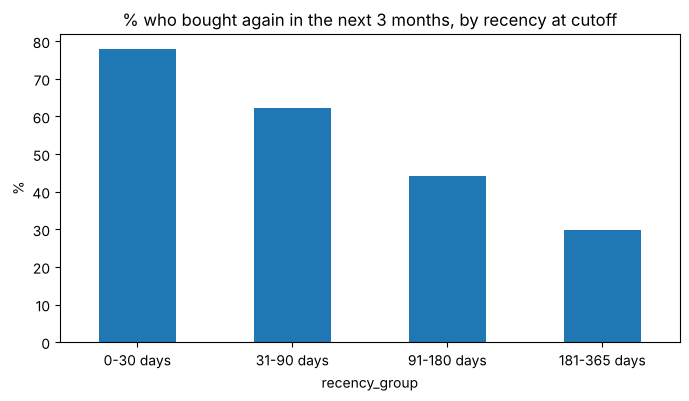

,customers,target rate %
recency_group,,
0-30 days,808,78.0
31-90 days,1009,62.2
91-180 days,849,44.1
181-365 days,1555,29.8


In [20]:
base['recency_group'] = pd.cut(base['recency_days'], bins=[0, 30, 90, 180, 365],
                               labels=['0-30 days', '31-90 days', '91-180 days', '181-365 days'])
by_recency = base.groupby('recency_group', observed=True)['target_purchased_next_3m'].agg(['count', 'mean'])
by_recency['mean'] = (by_recency['mean'] * 100).round(1)
by_recency.columns = ['customers', 'target rate %']
base = base.drop(columns='recency_group')

by_recency['target rate %'].plot(kind='bar', figsize=(8, 4))
plt.title('% who bought again in the next 3 months, by recency at cutoff')
plt.ylabel('%')
plt.xticks(rotation=0)
plt.show()
by_recency

Customers who bought recently are much more likely to buy again. This makes sense, so the features carry real signal.

## 5. Validation of the modelling base and date coverage

The modelling base must pass every check below before it is used to train a model.

| Group | What is checked |
|---|---|
| Date coverage | Windows are full months, back-to-back, do not overlap, avoid the partial month, and have no missing trading days |
| Eligibility | Every customer follows every eligibility rule |
| Completeness | One row per customer, no guests, no empty values |
| Valid ranges | Features and target are inside their allowed ranges |
| No leakage | Features use only data before the cutoff; the target uses only the performance window |
| Reconciliation | Totals match an independent recount from the transactions |

In [21]:
feature_cols = [c for c in base.columns if c not in ['customer_id', 'target_purchased_next_3m', 'target_revenue_next_3m']]


def run_checks(base, feature_tx, target_tx, obs_start, cutoff, perf_end, feature_cols=feature_cols):
    ids = set(base['customer_id'])
    obs_tx = known[(known['InvoiceDate'] >= obs_start) & (known['InvoiceDate'] < cutoff) & known['CustomerID'].isin(ids)]
    window_months = coverage[(coverage.index.to_timestamp() >= obs_start) & (coverage.index.to_timestamp() < perf_end)]
    window_days = calendar[(calendar['Date'] >= obs_start) & (calendar['Date'] < perf_end)]
    window_gaps = window_days[window_days['expected_trading_day'] & ~window_days['has_sales']]
    rebuilt = build_features(known[known['InvoiceDate'] < cutoff], ids)   # same features with ALL future data removed
    first = first_purchase.reindex(list(ids))

    return {
        # date coverage
        'Observation window = 12 full months': obs_start.day == 1 and obs_start + pd.DateOffset(months=12) == cutoff,
        'Performance window = 3 full months': cutoff.day == 1 and cutoff + pd.DateOffset(months=3) == perf_end,
        'Windows are back-to-back with no overlap': obs_start < cutoff < perf_end,
        'Performance window ends before the partial month': perf_end <= first_partial_month_start,
        'Every month in the windows has sales': len(window_months) == 15 and (window_months['invoices'] > 0).all(),
        'No missing trading days inside the windows': len(window_gaps) == 0,
        'All months in the windows are complete': window_months['complete_month'].all(),
        # eligibility
        'All customers come from the eligible list': ids <= eligible,
        'Every customer bought before the cutoff': (first < cutoff).all(),
        f'Every customer has >= {MIN_TENURE_DAYS} days of history': (base['tenure_days'] >= MIN_TENURE_DAYS).all(),
        'Every customer ordered in the observation window': (base['frequency_12m'] >= 1).all(),
        # completeness
        'One row per customer': base['customer_id'].is_unique,
        'No guest (empty) customer_id': base['customer_id'].notnull().all(),
        'Row count = final eligible count in the waterfall': len(base) == waterfall['Customers left'].iloc[-1],
        'No missing values': base.isnull().sum().sum() == 0,
        # valid ranges
        'Recency between 1 and 365 days': base['recency_days'].between(1, 365).all(),
        'Tenure >= recency': (base['tenure_days'] >= base['recency_days']).all(),
        'Monetary > 0': (base['monetary_12m'] > 0).all(),
        'Average order value = monetary / frequency': ((base['avg_order_value_12m']
                                                        - base['monetary_12m'] / base['frequency_12m']).abs() < 0.01).all(),
        'Active months between 1 and 12': base['active_months_12m'].between(1, 12).all(),
        'Orders in last 3 months <= orders in 12 months': (base['orders_last_3m'] <= base['frequency_12m']).all(),
        'is_uk is 0 or 1': base['is_uk'].isin([0, 1]).all(),
        'Target is 0 or 1': base['target_purchased_next_3m'].isin([0, 1]).all(),
        'Target rate between 5% and 95%': 0.05 <= base['target_purchased_next_3m'].mean() <= 0.95,
        'Target revenue > 0 only when target = 1': ((base['target_revenue_next_3m'] > 0)
                                                    == (base['target_purchased_next_3m'] == 1)).all(),
        # no leakage
        'Feature data is all before the cutoff': feature_tx['InvoiceDate'].max() < cutoff,
        'Target data is all inside the performance window': target_tx['InvoiceDate'].min() >= cutoff
                                                            and target_tx['InvoiceDate'].max() < perf_end,
        'Features are the same when all future data is deleted':
            set(feature_cols) <= set(rebuilt.columns)
            and rebuilt.reset_index()[feature_cols].equals(base.sort_values('customer_id').reset_index(drop=True)[feature_cols]),
        'No target column is used as a feature': not any(c.startswith('target') for c in feature_cols),
        'No feature is almost the same as the target (|corr| < 0.9)':
            (base[feature_cols].corrwith(base['target_purchased_next_3m']).abs() < 0.9).all(),
        # reconciliation
        'Total monetary = observation-window revenue of these customers': abs(base['monetary_12m'].sum() - obs_tx['Revenue'].sum()) < 0.01,
        'Total frequency = observation-window orders of these customers': base['frequency_12m'].sum()
                                                                          == obs_tx.groupby(['CustomerID', 'Invoice']).ngroups,
        'Target = 1 count = independent recount': base['target_purchased_next_3m'].sum()
            == len(ids & set(known[(known['InvoiceDate'] >= cutoff) & (known['InvoiceDate'] < perf_end)]['CustomerID'])),
        'Removed + eligible customers = all customers': waterfall['Customers removed'].sum() + len(base)
                                                        == df['CustomerID'].nunique(),
    }


feature_tx = known[(known['InvoiceDate'] < CUTOFF) & known['CustomerID'].isin(eligible)]
checks = run_checks(base, feature_tx, perf, obs_start, CUTOFF, perf_end)

validation = pd.DataFrame({'Check': list(checks.keys()), 'Result': ['PASS' if v else 'FAIL' for v in checks.values()]})
print('Checks passed:', (validation['Result'] == 'PASS').sum(), 'out of', len(validation))
validation

Checks passed: 34 out of 34


,Check,Result
0,Observation window = 12 full months,PASS
1,Performance window = 3 full months,PASS
2,Windows are back-to-back with no overlap,PASS
3,Performance window ends before the partial month,PASS
4,Every month in the windows has sales,PASS
5,No missing trading days inside the windows,PASS
6,All months in the windows are complete,PASS
7,All customers come from the eligible list,PASS
8,Every customer bought before the cutoff,PASS
9,Every customer has >= 30 days of history,PASS


In [22]:
assert all(checks.values()), 'Some checks failed: do not use this modelling base'
print('All checks passed. The modelling base is ready for modelling.')

All checks passed. The modelling base is ready for modelling.


### 5.1 Prove the checks work

I put a mistake into a copy of the data on purpose and run the same checks. Every mistake must make at least one check FAIL.

In [23]:
tests = []
def test_mistake(name, **changes):
    args = dict(base=base, feature_tx=feature_tx, target_tx=perf, obs_start=obs_start, cutoff=CUTOFF, perf_end=perf_end)
    args.update(changes)
    result = run_checks(**args)
    failed = [k for k, v in result.items() if not v]
    tests.append({'Mistake added': name, 'Checks failed': len(failed), 'Caught': len(failed) > 0,
                  'Failed checks': ', '.join(failed)})

test_mistake('Same customer twice', base=pd.concat([base, base.iloc[[0]]], ignore_index=True))

leaky = known[(known['InvoiceDate'] < perf_end) & known['CustomerID'].isin(eligible)]
test_mistake('Feature data includes dates after the cutoff (leakage)', feature_tx=leaky)

b = base.copy(); b.loc[0, 'target_purchased_next_3m'] = 2
test_mistake('Target value of 2', base=b)

b = base.copy(); b.loc[0, 'monetary_12m'] = np.nan
test_mistake('Empty value in a feature', base=b)

new_customer = int(first_purchase[first_purchase >= CUTOFF].index[0])
b = pd.concat([base, base.iloc[[0]].assign(customer_id=new_customer)], ignore_index=True)
test_mistake('Customer who first bought after the cutoff', base=b)

test_mistake('Performance window goes into partial December 2011', perf_end=pd.Timestamp('2011-12-31'))

b = base.copy(); b.loc[0, 'recency_days'] = 500
test_mistake('Recency longer than the observation window', base=b)

b = base.copy(); b['bought_again_flag'] = b['target_purchased_next_3m']
test_mistake('Target copied into a feature with an innocent name', base=b, feature_cols=feature_cols + ['bought_again_flag'])

tests = pd.DataFrame(tests)
print('Mistakes caught:', tests['Caught'].sum(), 'out of', len(tests))
tests

Mistakes caught: 8 out of 8


,Mistake added,Checks failed,Caught,Failed checks
0,Same customer twice,7,True,"One row per customer, Row count = final eligible count in the waterfall, Features are the same when all future data ..."
1,Feature data includes dates after the cutoff (leakage),1,True,Feature data is all before the cutoff
2,Target value of 2,3,True,"Target is 0 or 1, Target revenue > 0 only when target = 1, Target = 1 count = independent recount"
3,Empty value in a feature,5,True,"No missing values, Monetary > 0, Average order value = monetary / frequency, Features are the same when all future d..."
4,Customer who first bought after the cutoff,8,True,"All customers come from the eligible list, Every customer bought before the cutoff, Row count = final eligible count..."
5,Performance window goes into partial December 2011,5,True,"Performance window = 3 full months, Performance window ends before the partial month, Every month in the windows has..."
6,Recency longer than the observation window,3,True,"Recency between 1 and 365 days, Tenure >= recency, Features are the same when all future data is deleted"
7,Target copied into a feature with an innocent name,2,True,"Features are the same when all future data is deleted, No feature is almost the same as the target (|corr| < 0.9)"


In [24]:
assert tests['Caught'].all(), 'A mistake was not caught by the checks'
print('Every mistake was caught.')

Every mistake was caught.


## 6. Snapshots: out-of-time sample and feature stability

One modelling base is built at **one** cutoff date. To train a model properly and test it on a period it has never seen,
I build the **same base at 4 cutoff dates**, 3 months apart, with exactly the same rules:

| Snapshot cutoff | Role |
|---|---|
| 1-Dec-2010, 1-Mar-2011, 1-Jun-2011 | **Development**: used to train the model |
| 1-Sep-2011 (the modelling base above) | **Out-of-time test**: used to check the model on a later period |

The last development snapshot's target window ends on 31-Aug-2011, the day before the out-of-time cutoff,
so the test period is never seen during training.

In [25]:
SNAPSHOT_CUTOFFS = pd.to_datetime(['2010-12-01', '2011-03-01', '2011-06-01', '2011-09-01'])

def build_base(cutoff):
    # the same eligibility rules, features and target as sections 4.1 to 4.3, for any cutoff date
    o_start = cutoff - pd.DateOffset(months=OBSERVATION_MONTHS)
    p_end = cutoff + pd.DateOffset(months=PERFORMANCE_MONTHS)
    first = known.groupby('CustomerID')['InvoiceDate'].min()
    in_obs = set(known[(known['InvoiceDate'] >= o_start) & (known['InvoiceDate'] < cutoff)]['CustomerID'])
    ids = {c for c in in_obs if first[c] < cutoff and (cutoff - first[c]).days >= MIN_TENURE_DAYS}

    b = build_features(known, ids, cutoff, o_start)
    target_tx = known[(known['InvoiceDate'] >= cutoff) & (known['InvoiceDate'] < p_end) & known['CustomerID'].isin(ids)]
    b['target_purchased_next_3m'] = b.index.isin(target_tx['CustomerID']).astype(int)
    b['target_revenue_next_3m'] = target_tx.groupby('CustomerID')['Revenue'].sum().round(2).reindex(b.index).fillna(0)
    return b.reset_index(), o_start, p_end

snapshot_bases, rows = {}, []
for cutoff in SNAPSHOT_CUTOFFS:
    b, o_start, p_end = build_base(cutoff)
    snapshot_bases[cutoff] = (b, o_start, p_end)
    rows.append({'cutoff': cutoff.date(),
                 'role': 'Out-of-time test' if cutoff == SNAPSHOT_CUTOFFS[-1] else 'Development',
                 'observation_window': f"{o_start.date()} to {(cutoff - pd.Timedelta(days=1)).date()}",
                 'performance_window': f"{cutoff.date()} to {(p_end - pd.Timedelta(days=1)).date()}",
                 'eligible_customers': len(b),
                 'target_rate_%': round(b['target_purchased_next_3m'].mean() * 100, 1),
                 'avg_recency_days': round(b['recency_days'].mean(), 1),
                 'avg_frequency_12m': round(b['frequency_12m'].mean(), 2)})
snapshots = pd.DataFrame(rows)
snapshots

,cutoff,role,observation_window,performance_window,eligible_customers,target_rate_%,avg_recency_days,avg_frequency_12m
0,2010-12-01,Development,2009-12-01 to 2010-11-30,2010-12-01 to 2011-02-28,3913,33.8,93.7,4.55
1,2011-03-01,Development,2010-03-01 to 2011-02-28,2011-03-01 to 2011-05-31,4128,37.2,125.6,4.33
2,2011-06-01,Development,2010-06-01 to 2011-05-31,2011-06-01 to 2011-08-31,4214,36.7,134.0,4.20
3,2011-09-01,Out-of-time test,2010-09-01 to 2011-08-31,2011-09-01 to 2011-11-30,4221,49.7,147.4,4.16


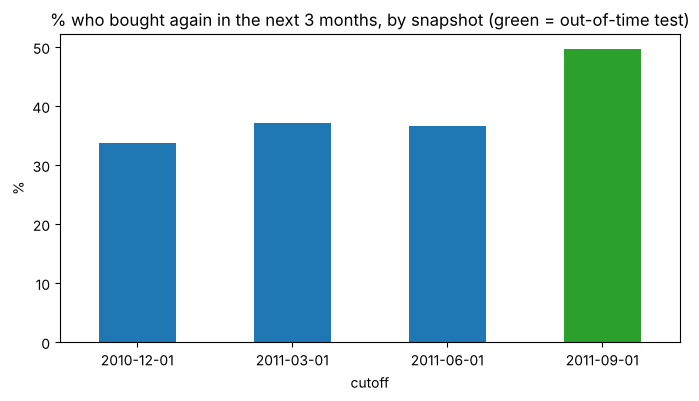

In [26]:
snapshots.plot(x='cutoff', y='target_rate_%', kind='bar', legend=False, figsize=(8, 4),
               color=['tab:blue', 'tab:blue', 'tab:blue', 'tab:green'])
plt.title('% who bought again in the next 3 months, by snapshot (green = out-of-time test)')
plt.ylabel('%')
plt.xticks(rotation=0)
plt.show()

**Seasonality:** the 1-Sep-2011 snapshot has a much higher target rate than the others, because its performance window
(September to November) is the Christmas buying season. A model trained on one season and used in another will be biased,
so the development data uses **3 snapshots from different seasons**.

In [27]:
# all snapshots in one table (a customer can appear in more than one snapshot)
all_snapshots = pd.concat([b.assign(snapshot_cutoff=c.date(),
                                    role='Out-of-time test' if c == SNAPSHOT_CUTOFFS[-1] else 'Development')
                           for c, (b, _, _) in snapshot_bases.items()], ignore_index=True)
print('Rows in all snapshots:', len(all_snapshots))
print('Development rows     :', (all_snapshots['role'] == 'Development').sum())
print('Out-of-time rows     :', (all_snapshots['role'] == 'Out-of-time test').sum())
print('Customers in more than one snapshot:', (all_snapshots['customer_id'].value_counts() > 1).sum())

Rows in all snapshots: 16476
Development rows     : 12255
Out-of-time rows     : 4221
Customers in more than one snapshot: 4572


Because the same customer can appear in several development snapshots, the training and validation split inside
the development data should be done **by customer**, so one customer is never on both sides.

### 6.1 Snapshot checks

In [28]:
latest_base = snapshot_bases[SNAPSHOT_CUTOFFS[-1]][0]
try:
    pd.testing.assert_frame_equal(latest_base, base)
    same_as_main = True
except AssertionError:
    same_as_main = False

dev_perf_ends = [p for c, (_, _, p) in snapshot_bases.items() if c != SNAPSHOT_CUTOFFS[-1]]
snapshot_checks = {
    'Out-of-time snapshot = the modelling base from section 4 (exactly)': same_as_main,
    'Every snapshot: observation window starts on or after the first data date':
        all(o >= data_start for _, o, _ in snapshot_bases.values()),
    'Every snapshot: performance window ends before the partial month':
        all(p <= first_partial_month_start for _, _, p in snapshot_bases.values()),
    'Every snapshot: windows are full months':
        all(c.day == 1 and o.day == 1 and p.day == 1 for c, (_, o, p) in snapshot_bases.items()),
    'Snapshots are 3 months apart':
        all(SNAPSHOT_CUTOFFS[i] + pd.DateOffset(months=3) == SNAPSHOT_CUTOFFS[i + 1] for i in range(len(SNAPSHOT_CUTOFFS) - 1)),
    'Development targets end on or before the out-of-time cutoff': max(dev_perf_ends) <= SNAPSHOT_CUTOFFS[-1],
    'Every snapshot: one row per customer': all(b['customer_id'].is_unique for b, _, _ in snapshot_bases.values()),
    'Every snapshot: no missing values': all(b.isnull().sum().sum() == 0 for b, _, _ in snapshot_bases.values()),
    'Every snapshot: target rate between 5% and 95%':
        all(0.05 <= b['target_purchased_next_3m'].mean() <= 0.95 for b, _, _ in snapshot_bases.values()),
    'Every snapshot: features only use data before its cutoff':
        all(build_features(known[known['InvoiceDate'] < c], set(b['customer_id']), c, o).reset_index()[feature_cols]
            .equals(b[feature_cols]) for c, (b, o, _) in snapshot_bases.items()),
}
snapshot_validation = pd.DataFrame({'Check': list(snapshot_checks.keys()),
                                    'Result': ['PASS' if v else 'FAIL' for v in snapshot_checks.values()]})
print('Snapshot checks passed:', (snapshot_validation['Result'] == 'PASS').sum(), 'out of', len(snapshot_validation))
assert all(snapshot_checks.values()), 'Some snapshot checks failed'
snapshot_validation

Snapshot checks passed: 10 out of 10


,Check,Result
0,Out-of-time snapshot = the modelling base from section 4 (exactly),PASS
1,Every snapshot: observation window starts on or after the first data date,PASS
2,Every snapshot: performance window ends before the partial month,PASS
3,Every snapshot: windows are full months,PASS
4,Snapshots are 3 months apart,PASS
5,Development targets end on or before the out-of-time cutoff,PASS
6,Every snapshot: one row per customer,PASS
7,Every snapshot: no missing values,PASS
8,Every snapshot: target rate between 5% and 95%,PASS
9,Every snapshot: features only use data before its cutoff,PASS


### 6.2 Feature stability (PSI)

The **Population Stability Index (PSI)** compares how a feature is spread in the development data with how it is spread in the
out-of-time data. A model works best when its features look the same in training and in use.

| PSI | Meaning |
|---|---|
| below 0.10 | Stable |
| 0.10 to 0.25 | Moderate shift: watch it |
| above 0.25 | Major shift: the feature behaves differently in the test period |

In [29]:
def psi(expected, actual, bins=10):
    if expected.nunique() <= 10:      # few values (for example is_uk): compare each value
        e = expected.value_counts(normalize=True)
        a = actual.value_counts(normalize=True)
        values = e.index.union(a.index)
        e, a = e.reindex(values, fill_value=0), a.reindex(values, fill_value=0)
    else:                             # many values: 10 groups made from the development data
        edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf
        e = pd.cut(expected, edges).value_counts(normalize=True, sort=False)
        a = pd.cut(actual, edges).value_counts(normalize=True, sort=False)
    e, a = e.clip(lower=0.0001), a.clip(lower=0.0001)
    return float(((a - e) * np.log(a / e)).sum())

development = all_snapshots[all_snapshots['role'] == 'Development']
out_of_time = all_snapshots[all_snapshots['role'] == 'Out-of-time test']

stability = pd.DataFrame({'feature': feature_cols,
                          'psi': [round(psi(development[c], out_of_time[c]), 3) for c in feature_cols]})
stability['status'] = pd.cut(stability['psi'], [-np.inf, 0.10, 0.25, np.inf],
                             labels=['Stable', 'Moderate shift', 'Major shift']).astype(str)
stability = stability.sort_values('psi', ascending=False).reset_index(drop=True)
stability

,feature,psi,status
0,tenure_days,0.910,Major shift
1,recency_days,0.208,Moderate shift
2,orders_same_period_last_year,0.073,Stable
3,revenue_last_3m,0.013,Stable
4,distinct_products_12m,0.006,Stable
5,frequency_12m,0.005,Stable
6,monetary_12m,0.005,Stable
7,orders_last_3m,0.005,Stable
8,units_12m,0.004,Stable
9,active_months_12m,0.004,Stable


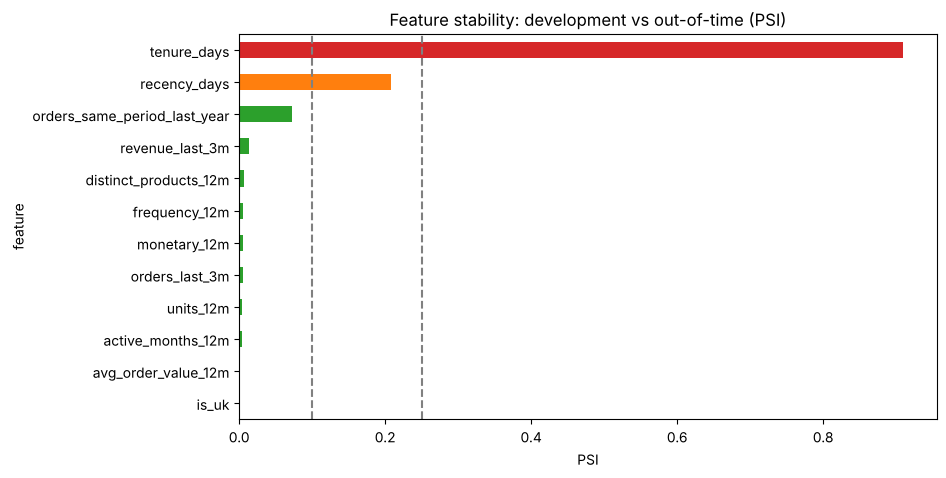

Stable features        : 10
Moderate shift features: ['recency_days']
Major shift features   : ['tenure_days']


In [30]:
colors = stability['status'].map({'Stable': 'tab:green', 'Moderate shift': 'tab:orange', 'Major shift': 'tab:red'})
stability.plot(x='feature', y='psi', kind='barh', legend=False, color=colors, figsize=(9, 5))
plt.axvline(0.10, color='grey', linestyle='--')
plt.axvline(0.25, color='grey', linestyle='--')
plt.gca().invert_yaxis()
plt.title('Feature stability: development vs out-of-time (PSI)')
plt.xlabel('PSI')
plt.show()

print('Stable features        :', (stability['status'] == 'Stable').sum())
print('Moderate shift features:', stability.loc[stability['status'] == 'Moderate shift', 'feature'].tolist())
print('Major shift features   :', stability.loc[stability['status'] == 'Major shift', 'feature'].tolist())

**Why `tenure_days` shifts so much:** the data only starts on 1-Dec-2009, so tenure can never be longer than the time since then.
At the 1-Dec-2010 cutoff a customer can have at most 365 days of tenure, and a customer who really started years ago but first appears
in the data in 2010 looks new. At later cutoffs there is more history. The shift comes from the **data start date**, not from customer behaviour.

I test fixes: capping tenure at a maximum value, and leaving out the earliest snapshot.

In [31]:
dev_without_first = development[development['snapshot_cutoff'] != SNAPSHOT_CUTOFFS[0].date()]
tenure_options = []
for dev_name, dev in [('All 3 development snapshots', development), ('Without the 1-Dec-2010 snapshot', dev_without_first)]:
    for cap in [None, 365, 180]:
        e = dev['tenure_days'] if cap is None else dev['tenure_days'].clip(upper=cap)
        o = out_of_time['tenure_days'] if cap is None else out_of_time['tenure_days'].clip(upper=cap)
        tenure_options.append({'development data': dev_name, 'tenure cap (days)': cap or 'no cap',
                               'psi': round(psi(e, o), 3)})
tenure_options = pd.DataFrame(tenure_options)
tenure_options['status'] = pd.cut(tenure_options['psi'], [-np.inf, 0.10, 0.25, np.inf],
                                  labels=['Stable', 'Moderate shift', 'Major shift']).astype(str)
tenure_options

,development data,tenure cap (days),psi,status
0,All 3 development snapshots,no cap,0.910,Major shift
1,All 3 development snapshots,365,0.506,Major shift
2,All 3 development snapshots,180,0.064,Stable
3,Without the 1-Dec-2010 snapshot,no cap,0.700,Major shift
4,Without the 1-Dec-2010 snapshot,365,0.152,Moderate shift
5,Without the 1-Dec-2010 snapshot,180,0.011,Stable


**Recommendations for modelling**
- Use `tenure_days` **capped at 180 days**. With the cap, tenure is stable (PSI 0.064) across all 3 development snapshots.
  Without it, the model would learn a difference that only comes from the data start date.
- `recency_days` has a moderate shift (PSI 0.208) because each cutoff falls in a different season. Keep it, since it is the strongest
  signal (section 4.4), but check the model on the out-of-time snapshot.
- The other 10 features are stable (PSI below 0.10).

## 7. Feature correlation

Features that carry almost the same information make a model harder to explain. I use **Spearman correlation**
(good for skewed data like money and order counts) and list pairs with |correlation| ≥ 0.80.

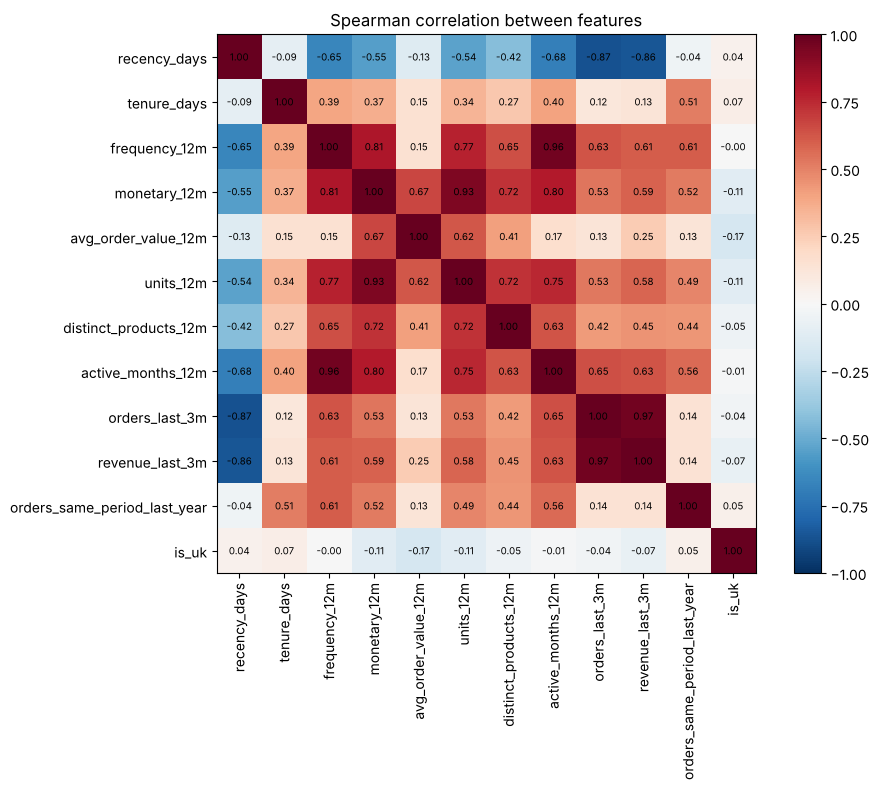

In [32]:
corr = base[feature_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=90)
ax.set_yticks(range(len(feature_cols)))
ax.set_yticklabels(feature_cols)
for i in range(len(feature_cols)):
    for j in range(len(feature_cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(im)
ax.set_title('Spearman correlation between features')
plt.tight_layout()
plt.show()

In [33]:
pairs = []
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        pairs.append({'feature_1': feature_cols[i], 'feature_2': feature_cols[j],
                      'spearman_corr': round(corr.iloc[i, j], 3)})
pairs = pd.DataFrame(pairs)
high_corr = pairs[pairs['spearman_corr'].abs() >= 0.80].sort_values('spearman_corr', ascending=False).reset_index(drop=True)
print('Feature pairs with |correlation| >= 0.80:', len(high_corr))
high_corr

Feature pairs with |correlation| >= 0.80: 6


,feature_1,feature_2,spearman_corr
0,orders_last_3m,revenue_last_3m,0.966
1,frequency_12m,active_months_12m,0.963
2,monetary_12m,units_12m,0.935
3,frequency_12m,monetary_12m,0.812
4,recency_days,revenue_last_3m,-0.855
5,recency_days,orders_last_3m,-0.869


**Recommendations:** each pair above carries almost the same information
(for example, orders and revenue in the last 3 months). Tree models (Random Forest, XGBoost) can handle this,
but for a linear model (Logistic Regression) keep **one feature from each pair** so the model stays easy to explain.

## 8. Save all results in one Excel file

Every result table goes on its own sheet of `Modelling_Base_Results.xlsx`.

In [34]:
data_dictionary = pd.DataFrame([
    ('customer_id', 'ID', 'Customer number'),
    ('recency_days', 'Feature', 'Days from the last order (in the observation window) to the cutoff'),
    ('tenure_days', 'Feature', 'Days from the first ever order to the cutoff'),
    ('frequency_12m', 'Feature', 'Orders in the 12-month observation window'),
    ('monetary_12m', 'Feature', 'Money spent in the observation window (GBP)'),
    ('avg_order_value_12m', 'Feature', 'monetary_12m / frequency_12m'),
    ('units_12m', 'Feature', 'Units bought in the observation window'),
    ('distinct_products_12m', 'Feature', 'Different products bought in the observation window'),
    ('active_months_12m', 'Feature', 'Months (out of 12) with at least one order'),
    ('orders_last_3m', 'Feature', 'Orders in the 3 months before the cutoff'),
    ('revenue_last_3m', 'Feature', 'Money spent in the 3 months before the cutoff'),
    ('orders_same_period_last_year', 'Feature', 'Orders in the same 3 months one year before the performance window'),
    ('is_uk', 'Feature', '1 if the customer\'s main country is the United Kingdom'),
    ('target_purchased_next_3m', 'Target', '1 if the customer ordered in the 3-month performance window'),
    ('target_revenue_next_3m', 'Target', 'Money spent in the performance window (do not use as a feature)'),
], columns=['Column', 'Type', 'Meaning'])

windows = pd.DataFrame([
    ('History', data_start.date(), (obs_start - pd.Timedelta(days=1)).date(), 'Tenure only'),
    ('Observation window', obs_start.date(), (CUTOFF - pd.Timedelta(days=1)).date(), 'Features'),
    ('Cutoff date', CUTOFF.date(), CUTOFF.date(), 'Nothing after this is used for features'),
    ('Performance window', CUTOFF.date(), (perf_end - pd.Timedelta(days=1)).date(), 'Target'),
    ('Excluded', perf_end.date(), data_end.date(), 'Partial month'),
], columns=['Window', 'Start', 'End', 'Used for'])

sheets = {
    'modelling_base': base,
    'eligibility_waterfall': waterfall,
    'modelling_windows': windows,
    'date_coverage_monthly': coverage.reset_index().astype({'Month': str}),
    'days_without_sales': no_sales[['Date', 'reason']],
    'data_dictionary': data_dictionary,
    'validation_checks': validation,
    'checks_test_results': tests,
    'cleaning_log': cleaning_log,
    'snapshots_summary': snapshots,
    'all_snapshots': all_snapshots,
    'snapshot_checks': snapshot_validation,
    'feature_stability_psi': stability,
    'feature_correlation': high_corr,
    'tenure_fix_options': tenure_options,
}
EXCEL_FILE = 'Modelling_Base_Results.xlsx'
with pd.ExcelWriter(EXCEL_FILE) as writer:
    for sheet, table in sheets.items():
        table.to_excel(writer, sheet_name=sheet, index=False)

# read the file back and check every sheet
saved = pd.read_excel(EXCEL_FILE, sheet_name=None)
for sheet, table in sheets.items():
    assert len(saved[sheet]) == len(table), f'Sheet {sheet} has the wrong number of rows'
    print(f'{sheet}: {len(saved[sheet])} rows - OK')
print('Saved', EXCEL_FILE, 'with', len(saved), 'sheets')

modelling_base: 4221 rows - OK
eligibility_waterfall: 4 rows - OK
modelling_windows: 5 rows - OK
date_coverage_monthly: 25 rows - OK
days_without_sales: 135 rows - OK
data_dictionary: 15 rows - OK
validation_checks: 34 rows - OK
checks_test_results: 8 rows - OK
cleaning_log: 8 rows - OK
snapshots_summary: 4 rows - OK
all_snapshots: 16476 rows - OK
snapshot_checks: 10 rows - OK
feature_stability_psi: 12 rows - OK
feature_correlation: 6 rows - OK
tenure_fix_options: 6 rows - OK
Saved Modelling_Base_Results.xlsx with 15 sheets


## 9. Summary

**Transaction timeline and date coverage**

| Item | Result |
|---|---|
| Date range | 01-Dec-2009 to 09-Dec-2011 (739 calendar days, 604 days with sales) |
| Days without sales | 135: 104 Saturdays, 17 UK bank holidays, 12 Christmas closure days, 2 Easter Sundays |
| Unexplained gaps (possible missing data) | 0 |
| Monthly coverage | 25 months, all with sales on 100% of expected trading days |
| Partial month | December 2011 (data ends 9 December), excluded from the windows |
| Rows without CustomerID | 22.6% overall (14.3% to 38.4% by month), excluded from the modelling base |
| Days between repeat orders | median 25 days; 83.2% within 90 days |

**Modelling base**

| Item | Result |
|---|---|
| Observation window (features) | 01-Sep-2010 to 31-Aug-2011 (12 full months) |
| Cutoff date | 01-Sep-2011 |
| Performance window (target) | 01-Sep-2011 to 30-Nov-2011 (3 full months) |
| Customers with a CustomerID | 5,852 |
| Removed: first purchase on/after cutoff | 628 |
| Removed: no order in observation window | 901 |
| Removed: less than 30 days of history | 102 |
| **Eligible modelling base** | **4,221 customers (72.1%)**, 12 features + 2 target columns |
| Target rate (bought again in next 3 months) | 49.7% (2,096 customers), a balanced target |
| Target rate by recency | 78.0% for 0-30 days, 29.8% for 181-365 days |
| Validation | 34 out of 34 checks passed |
| Mistakes caught by the checks | 8 out of 8 |

**Conclusion:** the transaction timeline has no missing data. All gaps are planned closures. The only problem is the
partial December 2011, and the windows avoid it. The modelling base has one row per eligible customer, uses only past
data for features and only the next 3 months for the target, and passed every date-coverage, eligibility, leakage and
reconciliation check. It is ready for model training.
Train on the 3 development snapshots (split by customer), test on the out-of-time snapshot, cap tenure at 180 days,
and watch the seasonal shift in recency.

**Version 2: snapshots, feature stability and correlation**

| Item | Result |
|---|---|
| Snapshots | 4 cutoffs, 3 months apart: 3 development (12,255 rows) + 1 out-of-time test (4,221 rows) |
| Target rate by snapshot | 33.8% (Dec-2010), 37.2% (Mar-2011), 36.7% (Jun-2011), 49.7% (Sep-2011, Christmas season) |
| Snapshot checks | 10 out of 10 passed; the out-of-time snapshot is exactly the modelling base |
| Feature stability (PSI) | 10 features stable; recency_days moderate shift (0.208); tenure_days major shift (0.910) |
| Fix for tenure_days | Cap at 180 days: PSI 0.064 (stable) |
| Highly correlated feature pairs (≥ 0.80) | 6 pairs; keep one of each pair for a linear model |

**Output:** one Excel file, `Modelling_Base_Results.xlsx`, with 15 sheets: modelling_base, eligibility_waterfall,
modelling_windows, date_coverage_monthly, days_without_sales, data_dictionary, validation_checks, checks_test_results, cleaning_log,
snapshots_summary, all_snapshots, snapshot_checks, feature_stability_psi, feature_correlation, tenure_fix_options

### Verify the summary numbers against the outputs

In [35]:
reasons = no_sales['reason'].value_counts()
summary_check = [
    ('Calendar days', 739, calendar_days),
    ('Days with sales', 604, trading_days),
    ('Days without sales', 135, len(no_sales)),
    ('Saturdays without sales', 104, reasons.get('Saturday (business closed)', 0)),
    ('Bank holidays without sales', 17, reasons.get('UK bank holiday', 0)),
    ('Christmas closure days', 12, reasons.get('Christmas / New Year closure', 0)),
    ('Easter Sundays', 2, reasons.get('Easter Sunday', 0)),
    ('Unexplained gaps', 0, len(unexplained_gaps)),
    ('Months', 25, len(coverage)),
    ('Months below 100% coverage', 0, int((coverage['coverage_%'] < 100).sum())),
    ('Partial month', '2011-12', str(coverage.index[~coverage['complete_month']][0])),
    ('Guest rows %', 22.6, round(df['CustomerID'].isnull().mean() * 100, 1)),
    ('Lowest monthly guest %', 14.3, coverage['guest_rows_pct'].min()),
    ('Highest monthly guest %', 38.4, coverage['guest_rows_pct'].max()),
    ('Median days between orders', 25.0, gaps.median()),
    ('% next order within 90 days', 83.2, round((gaps <= 90).mean() * 100, 1)),
    ('Customers with ID', 5852, waterfall['Customers left'].iloc[0]),
    ('Removed: new after cutoff', 628, waterfall['Customers removed'].iloc[1]),
    ('Removed: no order in observation window', 901, waterfall['Customers removed'].iloc[2]),
    ('Removed: short history', 102, waterfall['Customers removed'].iloc[3]),
    ('Eligible customers', 4221, len(base)),
    ('Eligible %', 72.1, waterfall['% of all customers left'].iloc[-1]),
    ('Features', 12, len(feature_cols)),
    ('Target = 1', 2096, base['target_purchased_next_3m'].sum()),
    ('Target rate %', 49.7, round(base['target_purchased_next_3m'].mean() * 100, 1)),
    ('Target rate 0-30 days', 78.0, by_recency.loc['0-30 days', 'target rate %']),
    ('Target rate 181-365 days', 29.8, by_recency.loc['181-365 days', 'target rate %']),
    ('Checks passed', 34, sum(checks.values())),
    ('Mistakes caught', 8, int(tests['Caught'].sum())),
    ('Snapshots', 4, len(snapshots)),
    ('Development rows', 12255, int((all_snapshots['role'] == 'Development').sum())),
    ('Out-of-time rows', 4221, int((all_snapshots['role'] == 'Out-of-time test').sum())),
    ('Target rate Dec-2010', 33.8, snapshots['target_rate_%'].iloc[0]),
    ('Target rate Mar-2011', 37.2, snapshots['target_rate_%'].iloc[1]),
    ('Target rate Jun-2011', 36.7, snapshots['target_rate_%'].iloc[2]),
    ('Target rate Sep-2011', 49.7, snapshots['target_rate_%'].iloc[3]),
    ('Snapshot checks passed', 10, sum(snapshot_checks.values())),
    ('Stable features', 10, int((stability['status'] == 'Stable').sum())),
    ('Recency PSI', 0.208, stability.set_index('feature').loc['recency_days', 'psi']),
    ('Tenure PSI', 0.91, stability.set_index('feature').loc['tenure_days', 'psi']),
    ('Tenure PSI capped at 180', 0.064, tenure_options.loc[(tenure_options['development data'] == 'All 3 development snapshots')
                                                          & (tenure_options['tenure cap (days)'] == 180), 'psi'].iloc[0]),
    ('Highly correlated pairs', 6, len(high_corr)),
    ('Excel sheets', 15, len(saved)),
]
summary_check = pd.DataFrame(summary_check, columns=['Item', 'Reported', 'Notebook output'])
summary_check['Match'] = summary_check['Reported'].astype(str) == summary_check['Notebook output'].astype(str)
print('Summary numbers matching the outputs:', summary_check['Match'].sum(), 'out of', len(summary_check))
assert summary_check['Match'].all(), 'Some summary numbers do not match the outputs'
summary_check

Summary numbers matching the outputs: 43 out of 43


,Item,Reported,Notebook output,Match
0,Calendar days,739,739,True
1,Days with sales,604,604,True
2,Days without sales,135,135,True
3,Saturdays without sales,104,104,True
4,Bank holidays without sales,17,17,True
5,Christmas closure days,12,12,True
6,Easter Sundays,2,2,True
7,Unexplained gaps,0,0,True
8,Months,25,25,True
9,Months below 100% coverage,0,0,True
